In [99]:
!pip install -q streamlit pandas numpy scikit-learn plotly

In [100]:
import os
import pandas as pd
import numpy as np


folders = ['customer-segmentation/data', 'customer-segmentation/src', 'customer-segmentation/outputs']
for folder in folders:
    os.makedirs(folder, exist_ok=True)

np.random.seed(42)
n_customers = 150
data = {
    'customer_id': range(1, n_customers + 1),
    'age': np.random.randint(18, 70, n_customers),
    'gender': np.random.choice(['Male', 'Female'], n_customers),
    'annual_income': np.random.randint(20000, 150000, n_customers),
    'purchase_frequency': np.random.randint(1, 50, n_customers),
    'average_order_value': np.random.uniform(10, 500, n_customers).round(2),
    'last_purchase_days': np.random.randint(1, 365, n_customers)
}

df = pd.DataFrame(data)
df.to_csv('customer-segmentation/data/customers.csv', index=False)
print("Project structure and customers.csv created successfully.")

Project structure and customers.csv created successfully.


In [101]:
#DATA PREPROCESSING
%%writefile customer-segmentation/src/preprocessing.py
import pandas as pd
from sklearn.preprocessing import StandardScaler

def preprocess_and_scale(df):
    df_clean = df.dropna().drop_duplicates().copy()


    features = ['age', 'annual_income', 'purchase_frequency', 'average_order_value', 'last_purchase_days']
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df_clean[features])

    return df_clean, scaled_data

Overwriting customer-segmentation/src/preprocessing.py


In [102]:
# Task 3: Customer Segmentation

#Implement K-Means clustering using Scikit-learn.
%%writefile customer-segmentation/src/clustering.py
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def apply_kmeans(scaled_data, df_clean, n_clusters=4):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(scaled_data)

    df_clean['Cluster'] = cluster_labels

    sil_score = silhouette_score(scaled_data, cluster_labels) if n_clusters > 1 else 0.0

    return df_clean, sil_score, kmeans

Overwriting customer-segmentation/src/clustering.py


In [103]:
import sys
import pandas as pd
import plotly.express as px

In [104]:
sys.path.append('customer-segmentation')

from src.preprocessing import preprocess_and_scale
from src.clustering import apply_kmeans


df = pd.read_csv('customer-segmentation/data/customers.csv')

df_clean, scaled_data = preprocess_and_scale(df)

segmented_df, sil_score, kmeans_model = apply_kmeans(scaled_data, df_clean, n_clusters=4)

distribution = segmented_df['Cluster'].value_counts().sort_index().reset_index()
distribution.columns = ['Cluster', 'Number of Customers']


display(distribution)


fig = px.bar(
    distribution,
    x='Cluster',
    y='Number of Customers',
    title="Customer Distribution by Cluster",
)

fig.show()

,Cluster,Number of Customers
0,0,34
1,1,41
2,2,39
3,3,36


In [105]:
%%writefile /content/customer-segmentation/src/visualization.py
import matplotlib.pyplot as plt
import seaborn as sns

def plot_total_customers(df):
    print(f"TOTAL CUSTOMERS: {len(df)}")


def plot_customer_distribution(df):
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x='Cluster', palette='viridis')
    plt.title('Customer Distribution by Cluster')
    plt.show()

def plot_avg_income(df):
    plt.figure(figsize=(8, 4))
    sns.barplot(data=df, x='Cluster', y='annual_income', palette='viridis', errorbar=None)
    plt.title('Average Annual Income by Cluster')
    plt.show()

def plot_purchase_frequency(df):
    plt.figure(figsize=(8, 4))
    sns.barplot(data=df, x='Cluster', y='purchase_frequency', palette='viridis', errorbar=None)
    plt.title('Average Purchase Frequency by Cluster')
    plt.show()

def plot_segmentation_scatter(df):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=df, x='annual_income', y='purchase_frequency',
                    hue='Cluster', palette='viridis', s=100)
    plt.title('Customer Segmentation: Income vs Purchase Frequency')
    plt.show()

Overwriting /content/customer-segmentation/src/visualization.py


TOTAL CUSTOMERS: 150


/content/customer-segmentation/src/visualization.py:10: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




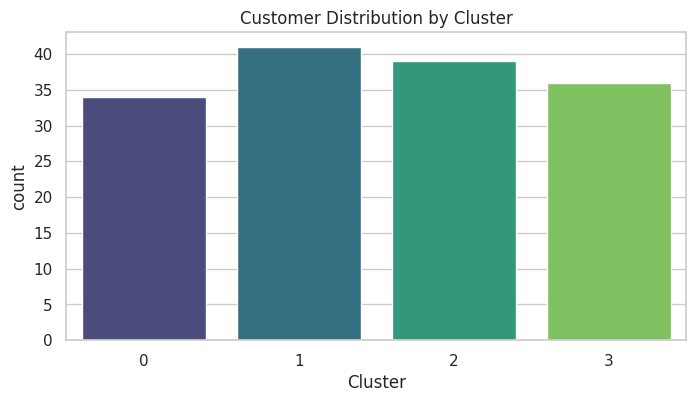

/content/customer-segmentation/src/visualization.py:16: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




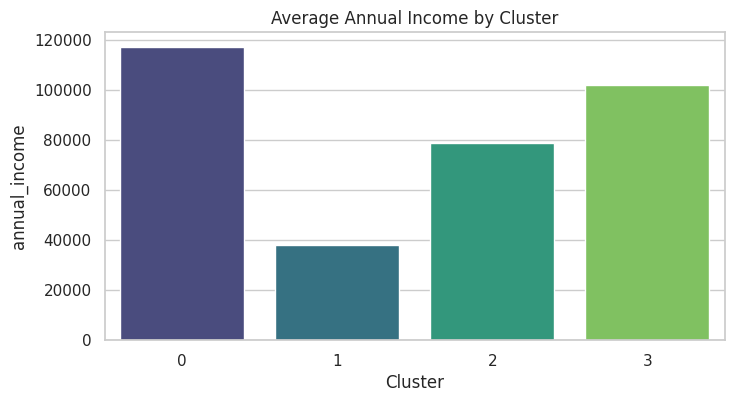

/content/customer-segmentation/src/visualization.py:22: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




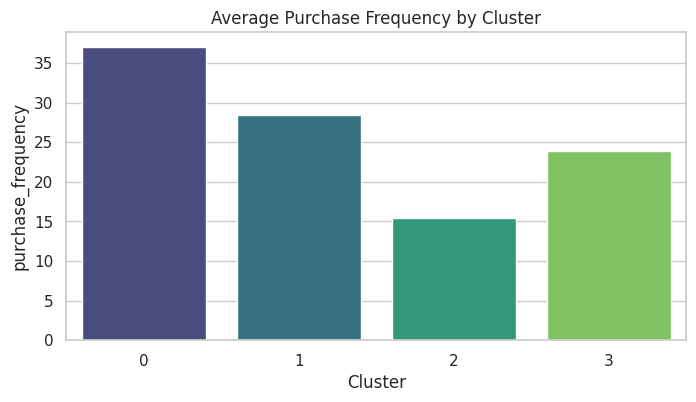

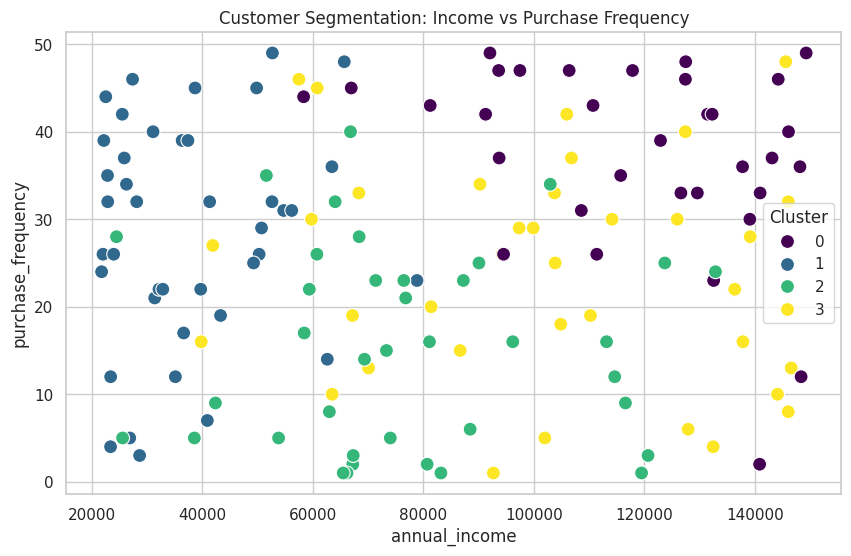

In [106]:
import sys
import importlib

if '/content/customer-segmentation' not in sys.path:
    sys.path.append('/content/customer-segmentation')

import src.visualization
importlib.reload(src.visualization)


from src.visualization import (
    plot_total_customers,
    plot_customer_distribution,
    plot_avg_income,
    plot_purchase_frequency,
    plot_segmentation_scatter
)

plot_total_customers(segmented_df)
plot_customer_distribution(segmented_df)
plot_avg_income(segmented_df)
plot_purchase_frequency(segmented_df)
plot_segmentation_scatter(segmented_df)

STREAMLIT FILE

In [107]:
%%writefile /content/customer-segmentation/app.py
import streamlit as st
import pandas as pd
import sys
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('/content/customer-segmentation')
from src.preprocessing import preprocess_and_scale
from src.clustering import apply_kmeans

st.set_page_config(page_title="Customer Analytics Dashboard", layout="wide")

st.title("Customer Analytics Dashboard")
st.write("---")


st.sidebar.header("Data Input")
uploaded_file = st.sidebar.file_uploader("Upload Customer Data (CSV)", type="csv")

if uploaded_file is None:
    st.info("Please upload your customer CSV file in the sidebar to begin analysis.")
    st.stop()

df = pd.read_csv(uploaded_file)
st.sidebar.success("CSV file successfully loaded!")

n_clusters = st.sidebar.slider("Number of Clusters", min_value=3, max_value=5, value=4)

if st.sidebar.button("Run Segmentation"):
    df_clean, scaled_data = preprocess_and_scale(df)
    segmented_df, sil_score, kmeans_model = apply_kmeans(scaled_data, df_clean, n_clusters=n_clusters)

    st.session_state['segmented_df'] = segmented_df
    st.session_state['sil_score'] = sil_score
    st.session_state['n_clusters'] = n_clusters


if 'segmented_df' in st.session_state:
    segmented_df = st.session_state['segmented_df']


    st.markdown(f"**- Total Customers:** {len(segmented_df)}")
    st.markdown(f"**- Number of Clusters:** {st.session_state['n_clusters']}")
    st.markdown(f"**- Silhouette Score:** {st.session_state['sil_score']:.3f}")

    st.write("")
    st.subheader("Customer Segments:")


    cluster_means = segmented_df.groupby('Cluster')[['annual_income', 'purchase_frequency', 'last_purchase_days']].mean()

    avg_income = segmented_df['annual_income'].mean()
    avg_freq = segmented_df['purchase_frequency'].mean()
    avg_recency = segmented_df['last_purchase_days'].mean()

    segments = []
    for cluster in cluster_means.index:
        inc = cluster_means.loc[cluster, 'annual_income']
        freq = cluster_means.loc[cluster, 'purchase_frequency']
        rec = cluster_means.loc[cluster, 'last_purchase_days']

        if rec > avg_recency * 1.2:
            group, desc = "At Risk", "Customers with a high number of days since last purchase"
        elif inc > avg_income and freq > avg_freq:
            group, desc = "High Value", "High income and high purchasing activity"
        elif freq < avg_freq * 0.8:
            group, desc = "Low Engagement", "Low purchasing frequency"
        else:
            group, desc = "Regular", "Moderate purchasing activity"

        segments.append({"Cluster": cluster, "Customer Group": group, "Description": desc})

    segments_df = pd.DataFrame(segments)
    st.table(segments_df.set_index("Cluster"))

    st.write("---")


    st.header("Cluster Visualizations")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.countplot(data=segmented_df, x='Cluster', ax=axes[0], palette='viridis')
    axes[0].set_title("Customer Distribution")

    sns.scatterplot(data=segmented_df, x='annual_income', y='purchase_frequency', hue='Cluster', palette='viridis', ax=axes[1])
    axes[1].set_title("Income vs Purchase Frequency")

    st.pyplot(fig)


    st.header("View and Filter Data")
    cluster_list = ["All"] + sorted(segmented_df['Cluster'].unique().tolist())
    selected_cluster = st.selectbox("Select Cluster to View", cluster_list)

    if selected_cluster == "All":
        display_df = segmented_df
    else:
        display_df = segmented_df[segmented_df['Cluster'] == selected_cluster]

    st.dataframe(display_df, use_container_width=True)


    st.header("Export Data")
    csv_data = display_df.to_csv(index=False).encode('utf-8')
    st.download_button(
        label="Download Segmented Data (CSV)",
        data=csv_data,
        file_name="segmented_customers.csv",
        mime="text/csv",
    )

Overwriting /content/customer-segmentation/app.py


In [109]:
# import urllib

# # Grab IP for the Localtunnel password
# ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip()
# print(f"IP ADDRESS: {ip}")

# # Run Streamlit with all security/caching flags disabled for Localtunnel
# !streamlit run /content/customer-segmentation/app.py \
#     --server.headless true \
#     --server.enableCORS false \
#     --server.enableXsrfProtection false \
#     & npx -y localtunnel --port 8501

In [110]:
!pkill -f streamlit
!pkill -f localtunnel
!pkill -f cloudflared

!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared

!nohup streamlit run /content/customer-segmentation/app.py --server.headless true > streamlit.log 2>&1 &

!nohup ./cloudflared tunnel --url http://localhost:8501 > tunnel.log 2>&1 &

import time
time.sleep(5)


print(" CLICK THE CLOUDFLARE LINK BELOW TO OPEN YOUR DASHBOARD:")
!grep -o 'https://.*\.trycloudflare.com' tunnel.log


 CLICK THE CLOUDFLARE LINK BELOW TO OPEN YOUR DASHBOARD:
https://gen-cast-hill-specifically.trycloudflare.com
